# Proyecto 2 ACTD — Reto Global Classroom: Analítica de Airbnb (Boston)
## Etapa 2: Extracción, limpieza y transformación de datos
**Rol:** Ingeniería de datos · **Fuente:** Inside Airbnb, `listings.csv` (Boston, scrape 2026-09-20)

Producto final de este notebook: `listings_clean.csv` (sin nulos, todo numérico/codificado) y `listings_clean_meta.json` (diccionario de decisiones).

**Estructura**
1. Carga y análisis exploratorio inicial
2. Selección de variables y eliminación de columnas inútiles
3. Variable objetivo (`price`)
4. Transformación y creación de características
5. Manejo de datos faltantes
6. Outliers
7. Codificación y dataset final
8. Verificación de requisitos

In [1]:
import json, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200, 'display.max_columns', 100, 'display.max_rows', 120)
sns.set_theme(style='whitegrid')

import os
PATH = next(p for p in ['../data/listings.csv','listings.csv'] if os.path.exists(p))
raw = pd.read_csv(PATH, low_memory=False)
df = raw.copy()
print('Filas, columnas:', raw.shape)

Filas, columnas: (4368, 90)


## 1. Análisis exploratorio inicial

In [2]:
tipos = raw.dtypes.astype(str).value_counts()
print(tipos, '\n')
resumen = pd.DataFrame({'dtype': raw.dtypes.astype(str), '%nulos': (raw.isna().mean()*100).round(1), 'n_unicos': raw.nunique()})
print('Columnas 100% vacías:', resumen.index[resumen['%nulos']==100].tolist())
print('Columnas constantes (<=1 valor):', resumen.index[resumen.n_unicos<=1].tolist())
resumen.sort_values('%nulos', ascending=False).head(30)

float64    36
str        29
int64      25
Name: count, dtype: int64 

Columnas 100% vacías: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']
Columnas constantes (<=1 valor): ['scrape_id', 'source', 'neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']


,dtype,%nulos,n_unicos
neighborhood_overview,float64,100.0,0
host_since,float64,100.0,0
host_response_time,float64,100.0,0
host_thumbnail_url,float64,100.0,0
host_acceptance_rate,float64,100.0,0
host_response_rate,float64,100.0,0
host_verifications,float64,100.0,0
neighbourhood,float64,100.0,0
host_total_listings_count,float64,100.0,0
host_neighbourhood,float64,100.0,0


**Hallazgos iniciales**
- 4.368 anuncios × 90 columnas; mezcla de numéricas, texto, URLs, fechas guardadas como texto y listas JSON (`amenities`).
- Esta versión del archivo trae **columnas completamente vacías** (`host_since`, `host_response_*`, `bathrooms`, `instant_bookable`, `calendar_updated`, etc.): hay que recuperar su información desde otras columnas (p. ej. `bathrooms_text`, `hosts_time_as_host_*`).
- `price` es texto con `$` y le falta ~20 % de los valores.
- Las reseñas (`review_scores_*`, `reviews_per_month`) faltan en ~18 %: son anuncios sin reseñas.

## 2. Selección de variables

In [3]:
vacias = resumen.index[resumen['%nulos']==100].tolist()
constantes = resumen.index[resumen.n_unicos<=1].tolist()
identificadores_url_texto = ['id','listing_url','picture_url','host_id','host_url','host_profile_id','host_profile_url','host_name',
    'host_picture_url','host_thumbnail_url','name','description','host_about','host_location','source','scrape_id']
# derivadas del precio o redundantes: se evita fuga de información hacia el objetivo
fuga_o_redundante = ['price_quote_checkin_date','price_quote_checkout_date','price_quote_total_price','price_quote_price_per_night','price_quote_raw',
    'estimated_revenue_l365d','last_scraped','calendar_last_scraped',
    'minimum_minimum_nights','maximum_minimum_nights','minimum_maximum_nights','maximum_maximum_nights','maximum_nights_avg_ntm',
    'availability_60','availability_90','availability_eoy','number_of_reviews_ly','host_total_listings_count',
    'calculated_host_listings_count_entire_homes','calculated_host_listings_count_private_rooms','calculated_host_listings_count_shared_rooms',
    'has_availability','bathrooms_text_dummy']
a_eliminar = sorted(set(vacias+constantes+identificadores_url_texto+fuga_o_redundante) & set(df.columns))
print(len(a_eliminar), 'columnas eliminadas')
# se conservan para derivar características antes de eliminarlas: amenities, bathrooms_text, license, hosts_time_*, first/last_review
conservar_para_derivar = ['amenities','bathrooms_text','license','first_review','last_review','price']
a_eliminar = [c for c in a_eliminar if c not in conservar_para_derivar]
df = df.drop(columns=a_eliminar)
print('Columnas restantes:', df.shape[1])

50 columnas eliminadas
Columnas restantes: 40


**Criterios:** se eliminan (a) columnas vacías o constantes, (b) identificadores, URLs y texto libre, (c) variables derivadas del precio (`price_quote_*`, `estimated_revenue_l365d`) por riesgo de fuga hacia el objetivo, y (d) variantes redundantes (p. ej. `minimum_minimum_nights` vs `minimum_nights`).

## 3. Variable objetivo: `price`

In [4]:
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[\$,]', '', regex=True), errors='coerce')
nulo = df['price'].isna()
print(f'Sin precio: {nulo.sum()} ({nulo.mean():.1%})')
print(df.groupby(nulo)[['number_of_reviews','availability_365','estimated_occupancy_l365d']].mean().round(1).rename(index={False:'con precio', True:'sin precio'}))

Sin precio: 882 (20.2%)
            number_of_reviews  availability_365  estimated_occupancy_l365d
price                                                                     
con precio               67.9             238.3                       97.7
sin precio               35.0             107.7                       33.2


Los anuncios sin precio son, en promedio, mucho menos activos (menos reseñas, ocupación estimada de ~33 vs ~98 días): suelen ser anuncios inactivos o bloqueados. **El objetivo no se imputa** (inventar el precio sesgaría los modelos); se eliminan esas filas.

In [5]:
df = df[~nulo].reset_index(drop=True)
print('Filas tras eliminar sin precio:', len(df))

Filas tras eliminar sin precio: 3486


## 4. Transformación y nuevas características

In [6]:
# 4.1 Baños: bathrooms está vacío, se recupera desde bathrooms_text
bt = df['bathrooms_text'].fillna('').str.lower()
df['bath_shared'] = bt.str.contains('shared').astype(int)
df['bath_private_only'] = bt.str.contains('private').astype(int)
num = bt.str.extract(r'(\d+\.?\d*)')[0].astype(float)
df['bathrooms'] = np.where(bt.str.contains('half'), 0.5, num)   # 'Half-bath' -> 0.5
df.loc[bt=='', 'bathrooms'] = np.nan
df = df.drop(columns='bathrooms_text')

# 4.2 Antigüedad del anfitrión (meses) a partir de años+meses
df['host_tenure_months'] = df['hosts_time_as_host_years']*12 + df['hosts_time_as_host_months']
df = df.drop(columns=['hosts_time_as_user_years','hosts_time_as_user_months','hosts_time_as_host_years','hosts_time_as_host_months'])

# 4.3 Booleanos t/f -> 0/1
for c in ['host_is_superhost','host_has_profile_pic','host_identity_verified']:
    df[c] = df[c].map({'t':1,'f':0})

# 4.4 Licencia: tiene registro STR o no
df['has_license'] = df['license'].notna().astype(int)
df = df.drop(columns='license')

# 4.5 Fechas (texto) -> antigüedad de reseñas
fs = pd.Timestamp('2026-09-20')
df['first_review'] = pd.to_datetime(df['first_review'], errors='coerce')
df['last_review']  = pd.to_datetime(df['last_review'],  errors='coerce')
df['days_since_first_review'] = (fs - df['first_review']).dt.days
df['days_since_last_review']  = (fs - df['last_review']).dt.days
df['has_reviews'] = df['first_review'].notna().astype(int)
df = df.drop(columns=['first_review','last_review'])

# 4.6 Amenities: lista JSON -> conteo + indicadores de las comodidades con frecuencia entre 5% y 95%
df['amenities_list'] = df['amenities'].apply(json.loads)
df['n_amenities'] = df['amenities_list'].str.len()
freq = pd.Series([a for l in df['amenities_list'] for a in l]).value_counts()/len(df)
elegidas = freq[(freq>=0.05)&(freq<=0.95)].index.tolist()
print(f'{len(freq)} amenities distintas; {len(elegidas)} con frecuencia entre 5% y 95%')
def slug(s): return 'am_' + re.sub(r'[^a-z0-9]+','_', s.lower()).strip('_')
am = pd.DataFrame({slug(a): df['amenities_list'].apply(lambda l, a=a: int(a in l)) for a in elegidas})
# se agrupan duplicados de nombre tras el slug
am = am.T.groupby(level=0).max().T
df = pd.concat([df.drop(columns=['amenities','amenities_list']), am], axis=1)
print('Nuevas columnas de amenities:', am.shape[1])

1284 amenities distintas; 99 con frecuencia entre 5% y 95%


Nuevas columnas de amenities: 99


In [7]:
# 4.7 Categóricas: agrupar categorías raras (consistencia de formato)
df['room_type'] = df['room_type'].str.strip().str.lower()
df['neighbourhood_cleansed'] = df['neighbourhood_cleansed'].str.strip()
top_pt = df['property_type'].value_counts().loc[lambda s: s>=40].index
df['property_type'] = df['property_type'].where(df['property_type'].isin(top_pt), 'Other').str.strip()
print(df['property_type'].value_counts(), '\n')
print(df['room_type'].value_counts())

property_type
Entire rental unit             1754
Private room in rental unit     429
Private room in home            319
Entire condo                    245
Room in hotel                   200
Entire home                     188
Other                           170
Entire serviced apartment        76
Entire guest suite               57
Private room in condo            48
Name: count, dtype: int64 

room_type
entire home/apt    2391
private room       1007
hotel room           84
shared room           4
Name: count, dtype: int64


## 5. Datos faltantes

In [8]:
nn = df.isna().sum(); nn = nn[nn>0]
print(pd.DataFrame({'nulos': nn, '%': (nn/len(df)*100).round(1)}))

                             nulos     %
beds                           113   3.2
minimum_nights                  36   1.0
maximum_nights                  36   1.0
review_scores_rating           484  13.9
review_scores_accuracy         484  13.9
review_scores_cleanliness      484  13.9
review_scores_checkin          484  13.9
review_scores_communication    484  13.9
review_scores_location         484  13.9
review_scores_value            484  13.9
reviews_per_month              484  13.9
bathrooms                       28   0.8
days_since_first_review        484  13.9
days_since_last_review         484  13.9


**Estrategia**
| Variable | Causa | Tratamiento |
|---|---|---|
| `review_scores_*`, `reviews_per_month` | anuncio sin reseñas | se conserva indicador `has_reviews`; ratings imputados con la **mediana** (reviews_per_month = 0) |
| `days_since_*_review` | sin reseñas | se imputa con el máximo observado (reseña "muy antigua") |
| `beds` | dato omitido | mediana por `accommodates` |
| `bathrooms` | texto ausente | mediana por `room_type` |
| `minimum_nights`, `maximum_nights` | omitido | mediana |

In [9]:
rs = [c for c in df.columns if c.startswith('review_scores_')]
df[rs] = df[rs].fillna(df[rs].median())
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
for c in ['days_since_first_review','days_since_last_review']:
    df[c] = df[c].fillna(df[c].max())
df['beds'] = df['beds'].fillna(df.groupby('accommodates')['beds'].transform('median')).fillna(df['beds'].median())
df['bathrooms'] = df['bathrooms'].fillna(df.groupby('room_type')['bathrooms'].transform('median'))
for c in ['minimum_nights','maximum_nights']:
    df[c] = df[c].fillna(df[c].median())
print('Nulos restantes:', int(df.isna().sum().sum()))

Nulos restantes: 0


## 6. Outliers

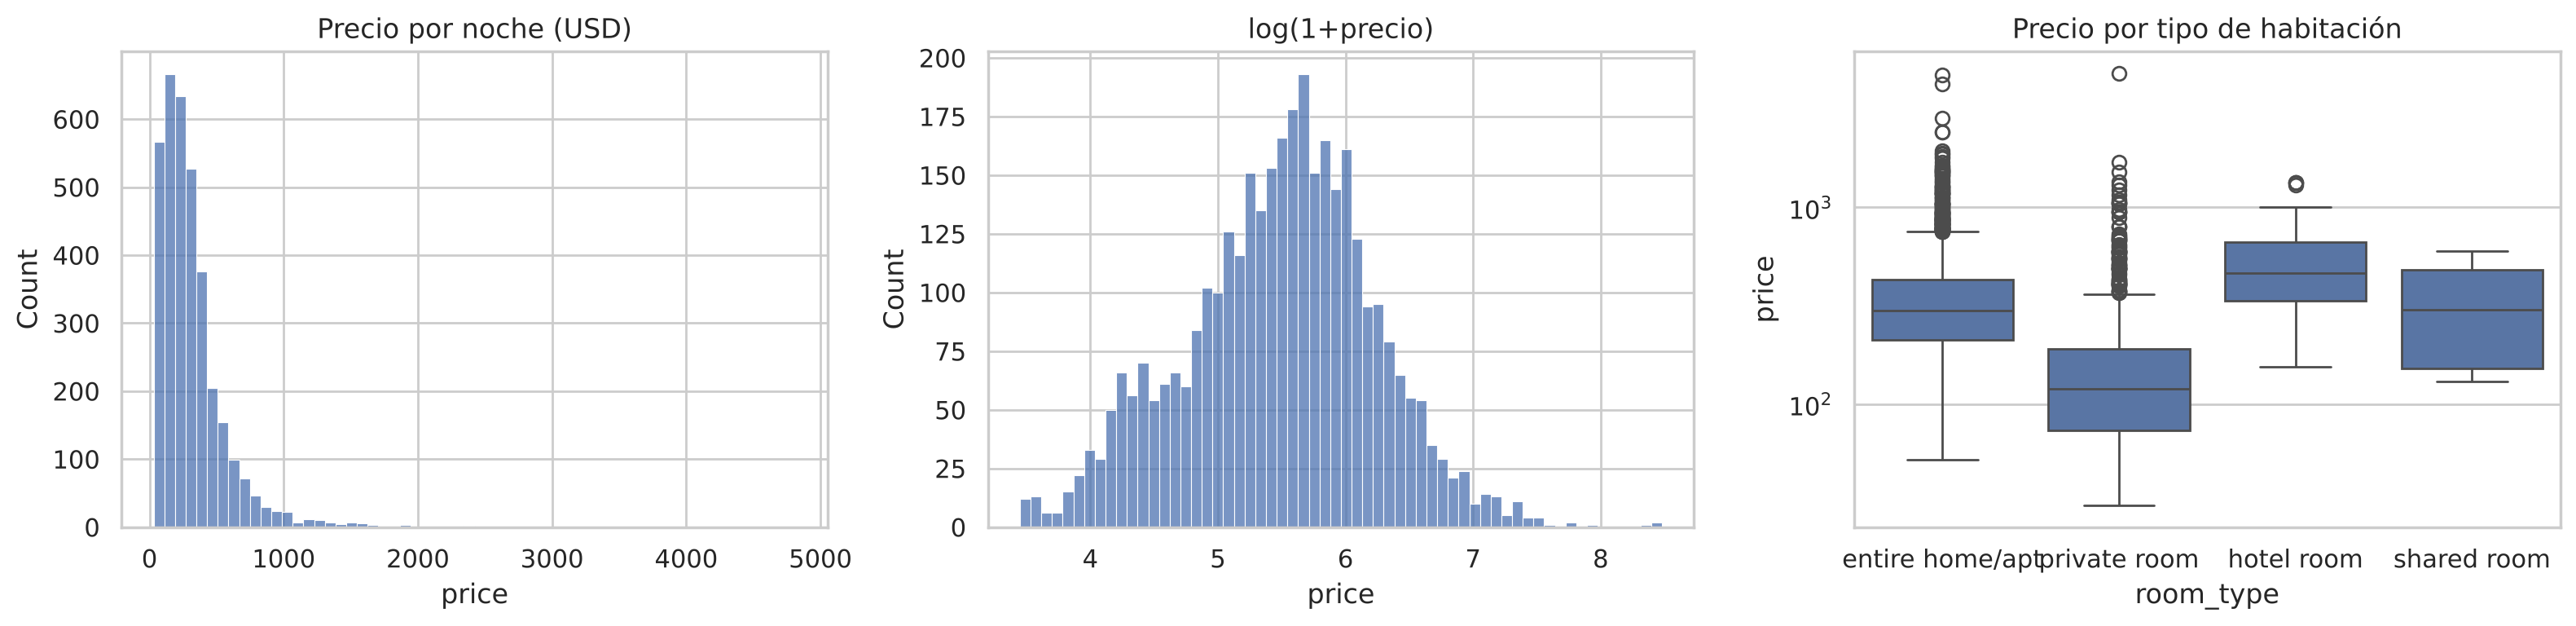

count    3486.0
mean      315.2
std       279.7
min        30.4
1%         41.9
5%         64.3
50%       253.3
95%       764.8
99%      1337.0
max      4815.0
Name: price, dtype: float64


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))
sns.histplot(df['price'], bins=60, ax=ax[0]).set(title='Precio por noche (USD)')
sns.histplot(np.log1p(df['price']), bins=60, ax=ax[1]).set(title='log(1+precio)')
sns.boxplot(data=df, x='room_type', y='price', ax=ax[2]).set(title='Precio por tipo de habitación', yscale='log')
plt.tight_layout(); plt.show()
print(df['price'].describe(percentiles=[.01,.05,.5,.95,.99]).round(1))

El precio es muy asimétrico a la derecha (se acerca a normal en escala log). Se usa la **regla del IQR sobre log(precio) dentro de cada `room_type`**: así un precio alto no se marca como atípico si es normal para apartamentos completos, pero sí si lo es para una habitación privada. Los casos marcados se eliminan.

In [11]:
logp = np.log(df['price'])
q1 = logp.groupby(df['room_type']).transform(lambda s: s.quantile(.25))
q3 = logp.groupby(df['room_type']).transform(lambda s: s.quantile(.75))
iqr = q3-q1
out_precio = (logp < q1-1.5*iqr) | (logp > q3+1.5*iqr)
print('Outliers de precio:', out_precio.sum(), f'({out_precio.mean():.1%})')
print(df.loc[out_precio, 'price'].describe().round(1))

Outliers de precio: 67 (1.9%)
count      67.0
mean     1387.5
std       903.7
min        52.1
25%      1009.0
50%      1333.5
75%      1569.6
max      4815.0
Name: price, dtype: float64


In [12]:
# Otras variables: valores imposibles / extremos (se acotan en lugar de eliminar filas)
print('minimum_nights >365:', (df.minimum_nights>365).sum(), '| maximum_nights >1125:', (df.maximum_nights>1125).sum())
df['minimum_nights'] = df['minimum_nights'].clip(upper=365)
df['maximum_nights'] = df['maximum_nights'].clip(upper=1125)
# anuncios con 0 camas/habitaciones se corrigen a un mínimo lógico
df['beds'] = df['beds'].clip(lower=1)
for c in ['host_listings_count','calculated_host_listings_count']:
    print(c, 'p99 =', df[c].quantile(.99), '-> winsorizado al p99')
    df[c] = df[c].clip(upper=df[c].quantile(.99))
df = df[~out_precio].reset_index(drop=True)
print('Filas finales tras outliers:', len(df))

minimum_nights >365: 0 | maximum_nights >1125: 8
host_listings_count p99 = 1508.0 -> winsorizado al p99
calculated_host_listings_count p99 = 118.0 -> winsorizado al p99
Filas finales tras outliers: 3419


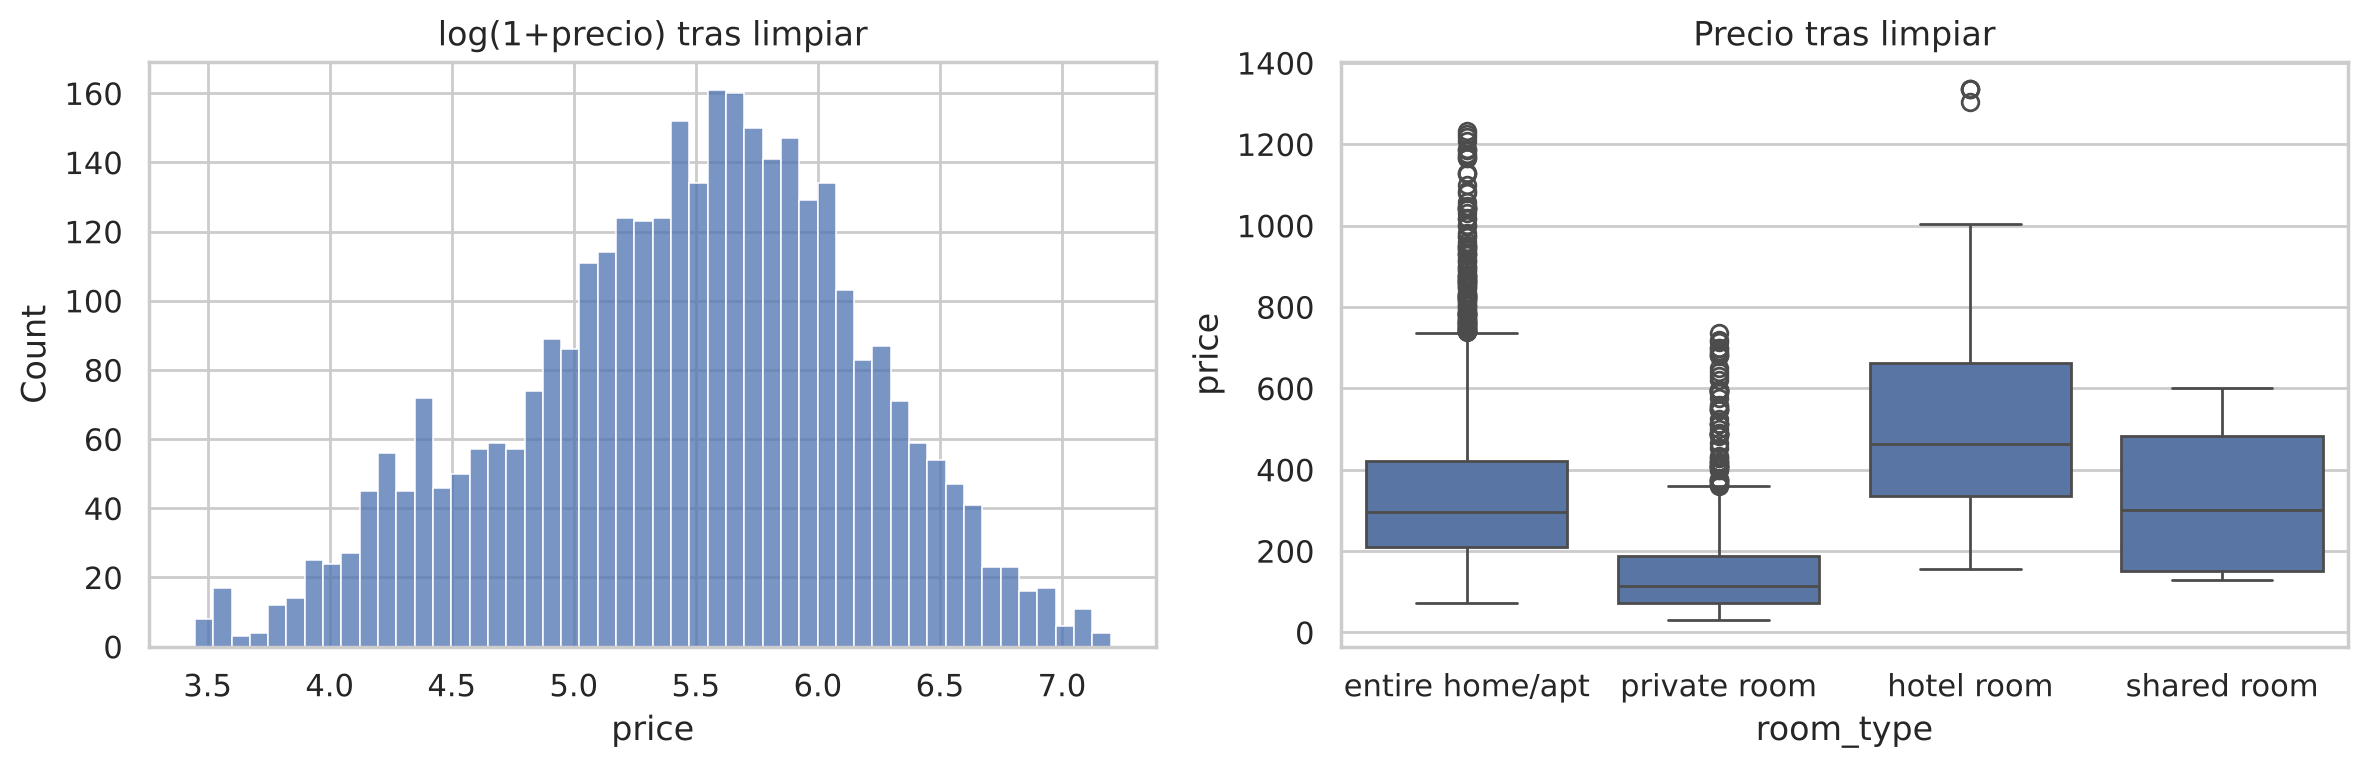

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(np.log1p(df['price']), bins=50, ax=ax[0]).set(title='log(1+precio) tras limpiar')
sns.boxplot(data=df, x='room_type', y='price', ax=ax[1]).set(title='Precio tras limpiar')
plt.tight_layout(); plt.show()

## 7. Codificación y dataset final

In [14]:
cat_cols = ['room_type','property_type','neighbourhood_cleansed']
final = pd.get_dummies(df, columns=cat_cols, prefix=['rt','pt','nb'], dtype=int)
final.columns = [re.sub(r'[^A-Za-z0-9_]+','_', c).strip('_').lower() for c in final.columns]
# ordenar: objetivo primero
cols = ['price'] + [c for c in final.columns if c!='price']
final = final[cols]
# variables binarias a int, numéricas a float/int
final = final.astype({c:'float64' for c in final.select_dtypes('number').columns if final[c].dtype=='float64'})
print(final.shape)
print(final.dtypes.value_counts())

(3419, 175)
int64      157
float64     18
Name: count, dtype: int64


Se codifican las categóricas con **one-hot** (`room_type`, `property_type`, `neighbourhood_cleansed`; 25 barrios → `nb_*`). El **escalado** de las numéricas **no** se aplica aquí: se hará dentro del pipeline de modelado, ajustado solo con el conjunto de entrenamiento (para evitar fuga de información), y es requisito para la red neuronal.

## 8. Verificación de requisitos y exportación

In [15]:
checks = {
 'Sin nulos': int(final.isna().sum().sum())==0,
 'Todo numérico (sin object/fecha)': all(np.issubdtype(t, np.number) for t in final.dtypes),
 'Sin columnas constantes': (final.nunique()<=1).sum()==0,
 'Sin anuncios duplicados (id único en origen)': raw['id'].is_unique,
 'Precio > 0': (final.price>0).all(),
}
for k,v in checks.items(): print(('OK  ' if v else 'FALLA'), k)
print('Nota:', int(final.duplicated().sum()), 'filas idénticas en atributos: son unidades distintas de un mismo edificio/anfitrión (mismo precio y características); se conservan.')
print('\nTamaño inicial:', raw.shape, '-> final:', final.shape)
final.to_csv('listings_clean.csv', index=False)
meta = {'filas_iniciales': int(len(raw)), 'filas_finales': int(len(final)), 'columnas_iniciales': int(raw.shape[1]), 'columnas_finales': int(final.shape[1]),
        'objetivo': 'price', 'amenities_codificadas': [c for c in final.columns if c.startswith('am_')]}
json.dump(meta, open('listings_clean_meta.json','w'), indent=2)
final.describe().T.head(25)

OK   Sin nulos
OK   Todo numérico (sin object/fecha)
OK   Sin columnas constantes
OK   Sin anuncios duplicados (id único en origen)
OK   Precio > 0
Nota: 9 filas idénticas en atributos: son unidades distintas de un mismo edificio/anfitrión (mismo precio y características); se conservan.

Tamaño inicial: (4368, 90) -> final: (3419, 175)


,count,mean,std,min,25%,50%,75%,max
price,3419.0,294.146479,202.462010,30.44000,149.000000,249.50000,385.000000,1337.00000
host_is_superhost,3419.0,0.437262,0.496121,0.00000,0.000000,0.00000,1.000000,1.00000
host_listings_count,3419.0,68.441065,214.707761,1.00000,3.000000,11.00000,43.000000,1508.00000
host_has_profile_pic,3419.0,0.988008,0.108864,0.00000,1.000000,1.00000,1.000000,1.00000
host_identity_verified,3419.0,0.967827,0.176486,0.00000,1.000000,1.00000,1.000000,1.00000
latitude,3419.0,42.335755,0.028767,42.23533,42.318010,42.34382,42.355051,42.39184
longitude,3419.0,-71.082575,0.032884,-71.17393,-71.099037,-71.07599,-71.061385,-70.99604
accommodates,3419.0,3.597251,2.686377,1.00000,2.000000,2.00000,4.000000,16.00000
bedrooms,3419.0,1.462416,1.151985,0.00000,1.000000,1.00000,2.000000,15.00000
beds,3419.0,2.056888,1.668486,1.00000,1.000000,1.00000,2.000000,21.00000
